# Songs 1970–1980: clusters by lyrics, instruments and country

**Research question.** To what extent can songs from 1970–1980 be grouped into meaningful clusters based on lyrical themes, country of origin and instrumentation, and how do these clusters correspond to established musical genres?

1. Clustering: do the song graphs have genuine community structure?
2. Associations between instrument, theme and country.
3. Alignment of the clusters with genre.

This notebook runs the whole analysis in order; the functions live in `src/`. The data decisions (genre labels, country, instrument families, which songs enter which graph) are explained in `Documentation.ipynb`. All randomness is driven by `SEED`. Figures go to `figures/` (PDF + PNG), tables to `results/`.

In [1]:
import os
# must be set before numpy is imported: works around a broken MKL OpenMP layer in our
# conda environment (see src/__init__.py); no effect without MKL
os.environ.setdefault("MKL_THREADING_LAYER", "TBB")

import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import networkx as nx

from src.config import SEED, FIG_DIR, RESULTS_DIR
from src.dataset import load_analysis_songs
from src import graphs, backbone as bb, plotting

FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
pd.set_option("display.width", 160)
ALPHA = 0.05   # disparity-filter significance level (Step 6C varies it)
plotting.use_style()
print("SEED =", SEED, "| ALPHA =", ALPHA)

SEED = 42 | ALPHA = 0.05


## Data

One row per song first released 1970–1980 (MusicBrainz), with Genius lyrics where matched. Songs whose lyrics are a near-copy of another song by the same artist are dropped as duplicates (spelling variants the title matching missed). Covers by other artists are kept.

Filler words are removed from the tokens when `config.REMOVE_FILLER_WORDS` is True. These are vocables like "ooh", "la" and "yeah", plus what spaCy leaves of contractions, like "gon" + "na" from "gonna" (lists in `src/text.py`). They make up about 10% of the tokens, and they would otherwise be among the most common top-10 words. Set the flag to False to undo it.

`genre_eval` is the evaluation genre: the vote-based coarse genre, with classes under 30 songs merged into "other". **Genre is only metadata: it is never used to build an edge.**

In [2]:
songs = load_analysis_songs()
lyr = songs[songs.has_lyrics]

coverage = pd.Series({
    "songs": len(songs),
    "with lyrics": songs.has_lyrics.sum(),
    "with instruments": songs.has_instruments.sum(),
    "with lyrics and instruments": (songs.has_lyrics & songs.has_instruments).sum(),
}, name="n")
display(coverage.to_frame())
display(lyr.genre_eval.value_counts(dropna=False).rename("songs with lyrics").to_frame())

Filler words removed: 9.5% of the lyrics tokens (config.REMOVE_FILLER_WORDS)


25491 songs 1970-1980 (23 lyric duplicates dropped): 7682 with lyrics, 2171 with instruments, 1428 with both


,n
songs,25491
with lyrics,7682
with instruments,2171
with lyrics and instruments,1428


,songs with lyrics
genre_eval,
rock,4103
rb,1320
pop,695
country,637
NaN,499
reggae,126
folk,122
other,92
electronic,47


## Step 1 — Three song graphs

| Graph | Songs | Edges |
|---|---|---|
| `G_lyrics` | all songs with lyrics | cosine similarity of TF-IDF vectors |
| `G_instruments` | all songs with instrument data | hyperbolic projection of song–instrument family |
| `G_combined` | songs with lyrics, instruments and country | hyperbolic projection of song–(instrument family, country, top-10 words) |

There is no country-only graph: projecting song–country would just give one clique per country. Country is used as metadata (like genre) and as a feature inside `G_combined`.

### G_lyrics

TF-IDF on the spaCy tokens (used as they are), with `min_df=2` (a word must occur in two songs to link them), `max_df=0.5` (words in more than half the songs are near-stop words) and `sublinear_tf=True` (tf = 1 + ln count, so a repeated chorus word cannot dominate). Rows are L2-normalised, so their dot product is the cosine similarity.

Almost every pair of songs shares some word, so the full similarity graph is 87% complete (≈25.8M edges). That is too dense for networkx, but fits as a dense 7,682 × 7,682 matrix. So `G_lyrics` is kept as the matrix `S` and only becomes a networkx graph after the disparity filter (Step 2).

In a first test on the 1970–1975 songs, we kept only each song's 20 most similar songs, but then the disparity filter kept just 95 edges. A song's 20 nearest neighbours all have similar weights, so none of them stands out against the others; the weak edges the filter needs as contrast are exactly the ones a top-k cut removes.

In [3]:
X, terms = graphs.tfidf(lyr.tokens)
S_lyrics = graphs.lyrics_similarity(X)      # G_lyrics as a dense weight matrix
lyrics_ids = lyr.index.to_numpy()
print(f"TF-IDF vocabulary: {len(terms)} words")
graphs.dense_summary(S_lyrics)

TF-IDF vocabulary: 12204 words


{'nodes': 7682,
 'edges': 25756510,
 'density': 0.8730215087618528,
 'components': 2,
 'isolated': 1,
 'lcc_nodes': 7681,
 'lcc_share': np.float64(0.9998698255662588)}

### G_instruments

Bipartite graph of songs and instrument families (`bipartite=0/1`), projected onto the songs with Newman's hyperbolic weighting (`collaboration_weighted_projected_graph`). A family shared by *k* songs adds 1/(*k*−1) to each of their pairs. So guitar, bass and drums, which are on 80–85% of the songs, add very little to any single pair, while a rare shared family (harmonica, folk strings) adds a lot. The projection is still almost complete, because nearly every pair shares guitar, bass or drums. The disparity filter will remove those weak links.

In [4]:
B_instruments = graphs.bipartite_graph(graphs.instrument_features(songs))
G_instruments = graphs.add_metadata(graphs.project(B_instruments), songs)
graphs.summary(G_instruments)

{'nodes': 2171,
 'edges': 2174578,
 'density': 0.9231779616944771,
 'components': 1,
 'isolated': 0,
 'lcc_nodes': 2171,
 'lcc_share': 1.0}

### G_combined

Songs link to three kinds of feature nodes: `inst:<family>`, `country:<release country>` and `word:<w>` for the song's 10 highest-TF-IDF words. The words are the lyrical themes, taken from the same TF-IDF as `G_lyrics`, so the IDF is estimated on all songs with lyrics.

**Balanced projection.** Each feature type gets its own bipartite graph and hyperbolic projection. Each projection's weights are scaled to sum to 1, and the three are added edge by edge (`graphs.balanced_projection`), so instruments, country and words count equally in total.

We first projected all features in one bipartite graph. A feature of degree *k* gives each of its pairs 1/(*k*−1): a word shared by just two songs gives weight 1, while "guitar" (≈1,260 songs) gives 0.0008. The disparity filter then kept almost only word edges, and words carried 96% of the backbone's weight, so `G_combined` was in effect a lyrics graph. The table shows the shares in that single projection, for comparison.

In [5]:
words = dict(zip(lyr.index, graphs.top_words(X, terms)))
combined_feats = graphs.combined_features(songs, words)
G_combined = graphs.add_metadata(graphs.balanced_projection(combined_feats), songs)

B_combined = graphs.bipartite_graph(combined_feats)   # single projection, for comparison only
display(pd.DataFrame({"single projection": graphs.feature_weight_shares(B_combined),
                      "balanced (used)": graphs.type_shares(G_combined)}).round(3))
feature_nodes = [n for n, b in B_combined.nodes(data="bipartite") if b == 1]
print(f"{len(feature_nodes)} feature nodes, {sum(B_combined.degree(f) == 1 for f in feature_nodes)} "
      "of them on a single song (they link nobody)")
graphs.summary(G_combined)

,single projection,balanced (used)
word,0.592,0.333
inst,0.332,0.333
country,0.077,0.333


5926 feature nodes, 3324 of them on a single song (they link nobody)


{'nodes': 1428,
 'edges': 962985,
 'density': 0.9451425980343083,
 'components': 1,
 'isolated': 0,
 'lcc_nodes': 1428,
 'lcc_share': 1.0}

In [6]:
from collections import Counter
print("Most common top-10 words over the songs with lyrics:")
print(Counter(w for ws in words.values() for w in ws).most_common(25))

Most common top-10 words over the songs with lyrics:
[('baby', 409), ('love', 343), ('wanna', 218), ('girl', 188), ('want', 182), ('need', 177), ('let', 177), ('dance', 156), ('tonight', 154), ('rock', 147), ('woman', 142), ('yes', 139), ('tell', 137), ('life', 137), ('world', 136), ('man', 135), ('come', 134), ('got', 133), ('feel', 129), ('little', 128), ('good', 126), ('alright', 126), ('away', 124), ('sweet', 123), ('loving', 121)]


In [7]:
step1 = pd.DataFrame({"G_lyrics": graphs.dense_summary(S_lyrics),
                      "G_instruments": graphs.summary(G_instruments),
                      "G_combined": graphs.summary(G_combined)}).T
step1["avg_degree"] = 2 * step1.edges / step1.nodes
step1.to_csv(RESULTS_DIR / "step1_graphs.csv")
step1.round(4)

,nodes,edges,density,components,isolated,lcc_nodes,lcc_share,avg_degree
G_lyrics,7682.0,25756510.0,0.8730,2.0,1.0,7681.0,0.9999,6705.6782
G_instruments,2171.0,2174578.0,0.9232,1.0,0.0,2171.0,1.0000,2003.2962
G_combined,1428.0,962985.0,0.9451,1.0,0.0,1428.0,1.0000,1348.7185


## Step 2 — Backbones with the disparity filter

The graphs are dense (the projections are more than 90% complete) and their edge weights are broadly distributed (figure below). A global weight threshold would keep every edge of the strong songs and none of the weak ones. The disparity filter (Serrano, Boguñá & Vespignani 2009) tests each edge against its own endpoints instead. Seen from song *u*, with strength *s_u* and degree *k_u*,

$$p_u(u,v) = \left(1 - \frac{w_{uv}}{s_u}\right)^{k_u - 1}$$

is the probability that a uniformly random split of *u*'s strength over its *k_u* edges gives one edge at least *w_uv*. The edge is kept if *p* < α from **either** endpoint, so it is enough that it matters to one of the two songs. The single edge of a degree-1 song is always kept. We use α = 0.05 (Step 6C repeats everything with 0.01 and 0.1). Our implementation (`src/backbone.py`) matches a direct edge-by-edge loop over the formula on 200-song test graphs, at all three α values.

### Edge weights before backboning

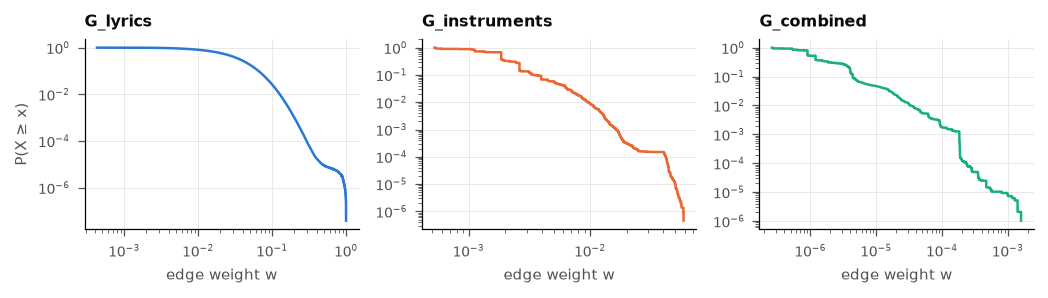

In [8]:
weights = {"G_lyrics": graphs.upper_weights(S_lyrics),
           "G_instruments": [w for *_, w in G_instruments.edges(data="weight")],
           "G_combined": [w for *_, w in G_combined.edges(data="weight")]}
fig = plotting.ccdf_panels(weights, "edge weight w", name="edge_weight_ccdf")

### Backbones

The p-values are computed once per graph. `backbone(P, alpha)` is then just a threshold, which makes the α sensitivity check in Step 6C cheap. `G_lyrics` is filtered on its dense matrix (`disparity_pvalues_dense`), which gives the same p-values as the graph version (tested in `src/backbone.py`). Community detection uses each backbone's largest connected component (LCC).

In [9]:
P = {"G_lyrics": graphs.add_metadata(bb.disparity_pvalues_dense(S_lyrics, lyrics_ids, keep_below=0.1), songs),
     "G_instruments": bb.disparity_pvalues(G_instruments),
     "G_combined": bb.disparity_pvalues(G_combined)}
before = {"G_lyrics": graphs.dense_summary(S_lyrics),
          "G_instruments": graphs.summary(G_instruments),
          "G_combined": graphs.summary(G_combined)}

backbones, lcc, rows = {}, {}, []
for name, Pg in P.items():
    backbones[name] = bb.backbone(Pg, ALPHA)
    lcc[name] = bb.largest_component(backbones[name])
    b, a = before[name], graphs.summary(backbones[name])
    rows.append({"graph": name, "nodes": b["nodes"],
                 "edges_before": b["edges"], "edges_after": a["edges"], "edges_kept": a["edges"] / b["edges"],
                 "density_before": b["density"], "density_after": a["density"],
                 "components_before": b["components"], "components_after": a["components"],
                 "isolated_after": a["isolated"], "lcc_nodes": lcc[name].number_of_nodes(),
                 "songs_dropped": b["nodes"] - lcc[name].number_of_nodes(),
                 "lcc_edges": lcc[name].number_of_edges()})
step2 = pd.DataFrame(rows).set_index("graph")
step2.to_csv(RESULTS_DIR / "step2_backbone.csv")
step2.T.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

graph,G_lyrics,G_instruments,G_combined
nodes,"7,682","2,171","1,428"
edges_before,2.576e+07,2.175e+06,9.63e+05
edges_after,9.926e+05,5.425e+04,4.64e+04
edges_kept,0.03854,0.02495,0.04818
density_before,0.873,0.9232,0.9451
density_after,0.03364,0.02303,0.04554
components_before,2,1,1
components_after,2,"1,201",1
isolated_after,1,"1,200",0
lcc_nodes,"7,681",971,"1,428"


### What the instrument backbone drops

In `G_instruments`, a song whose instrument families are all common (e.g. bass + drums + guitar) has nearly equal weights to every other song. None of its edges stands out, so the filter removes them all, and 1,200 of the 2,171 songs end up isolated. We keep the families and treat this as a result: a standard rock line-up carries no distinguishing instrument information.

With the original instrument names more songs would stay in the LCC (500 instead of 299 in a first test on 1970–1975), but part of what separates them is just how the credits are written ("bass" vs "bass guitar"). The table shows the most common family sets and the share of their songs in the LCC.

In [10]:
inst = songs[songs.has_instruments].assign(in_lcc=lambda d: d.index.isin(lcc["G_instruments"].nodes))
(inst.groupby("instrument_families").in_lcc.agg(songs="size", share_in_lcc="mean")
     .sort_values("songs", ascending=False).head(12).round(2))

,songs,share_in_lcc
instrument_families,,
bass;drums;guitar,385,0.0
bass;drums;guitar;keys,250,0.0
bass;drums;guitar;keys;percussion,114,0.0
bass;guitar;percussion,69,0.0
guitar,56,0.0
bass;drums;guitar;percussion,54,0.0
keys,50,0.0
bass;drums;guitar;keys;percussion;synth,48,1.0
bass;drums;guitar;keys;synth,42,1.0


### Which features hold G_combined's backbone together

Every edge stores its weight from each feature type. The types have equal shares before the filter, by construction. After the filter, the shares show which types produce edges that stand out for their songs.

In [11]:
pd.DataFrame({"before backbone": graphs.type_shares(G_combined),
              "backbone LCC": graphs.type_shares(lcc["G_combined"])}).round(3)

,before backbone,backbone LCC
inst,0.333,0.037
country,0.333,0.282
word,0.333,0.680


## Step 3 — Descriptive statistics of the backbones

The statistics describe the graphs communities will be found in: each backbone (α = 0.05) and its largest connected component (LCC). The unfiltered projections are almost complete graphs, so their degrees and clustering say little.

- **Degree distribution.** A CCDF on log-log axes, P(K ≥ k), which needs no binning. We only describe its shape and don't fit a power law.
- **Clustering.** The average local clustering coefficient, unweighted (as in the course) and weighted (Onnela's geometric-mean version, `nx.average_clustering(weight=...)`). It is compared with two random baselines:
  - an Erdős–Rényi graph of the same density, where *C* = density;
  - the configuration model with the same degrees, where *C* = (⟨k²⟩ − ⟨k⟩)² / (⟨k⟩³ *N*).

  If *C* is well above both, songs form more triangles than their degrees alone would produce, i.e. there are local groups of mutually similar songs.

In [12]:
rows = {}
for name in backbones:
    full, d = graphs.summary(backbones[name]), graphs.degree_stats(lcc[name])
    rows[name] = {"backbone_nodes": full["nodes"], "backbone_edges": full["edges"],
                  "components": full["components"], "isolated": full["isolated"],
                  "lcc_nodes": d["nodes"], "lcc_share": d["nodes"] / full["nodes"], "lcc_edges": d["edges"],
                  "avg_degree": d["avg_degree"], "median_degree": d["median_degree"], "max_degree": d["max_degree"],
                  "avg_clustering": d["avg_clustering"], "avg_clustering_weighted": d["avg_clustering_weighted"],
                  "C_rand (ER)": d["C_rand"], "C_conf (config.)": d["C_conf"],
                  "C / C_conf": d["avg_clustering"] / d["C_conf"]}
step3 = pd.DataFrame(rows)
step3.T.to_csv(RESULTS_DIR / "step3_descriptive.csv")
step3.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

,G_lyrics,G_instruments,G_combined
backbone_nodes,"7,682","2,171","1,428"
backbone_edges,9.926e+05,5.425e+04,4.64e+04
components,2,"1,201",1
isolated,1,"1,200",0
lcc_nodes,"7,681",971,"1,428"
lcc_share,0.9999,0.4473,1
lcc_edges,9.926e+05,5.425e+04,4.64e+04
avg_degree,258.4,111.7,64.98
median_degree,233,124,57
max_degree,"1,593",351,197


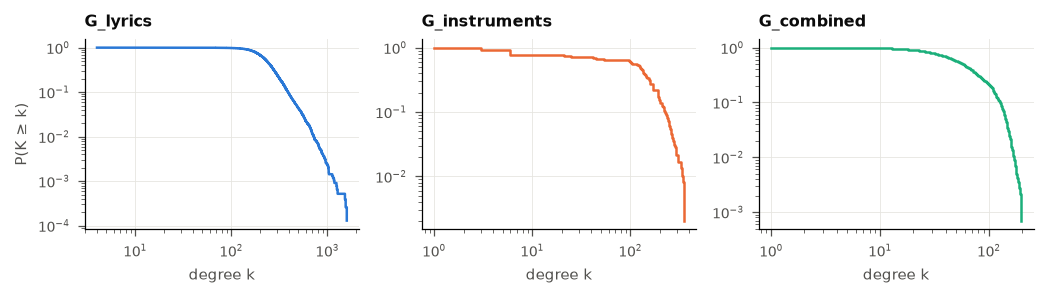

In [13]:
degrees = {name: [d for _, d in g.degree()] for name, g in lcc.items()}
fig = plotting.ccdf_panels(degrees, "degree k", name="degree_ccdf", ylabel="P(K ≥ k)")

## Step 4 — Louvain communities

Louvain (`nx.community.louvain_communities(G, weight="weight", seed=SEED)`) maximises the weighted modularity

$$M = \frac{1}{2W}\sum_{ij}\left(w_{ij} - \frac{s_i s_j}{2W}\right)\delta(c_i, c_j),$$

the share of edge weight inside communities minus what is expected if the same node strengths *s* were wired at random. It runs on each backbone's LCC. Communities are numbered by size (0 = largest) and stored on the nodes as `community`. Louvain is randomised, so Step 6C repeats it with 20 seeds.

Modularity has a resolution limit: groups smaller than about √(2W) cannot be resolved, so small genres may be merged into bigger communities. Communities with fewer than 10 songs are counted, but not described in Step 6D. Louvain's result also depends on the order in which nodes are stored, not only on the seed. Python orders strings differently in every new process, so the same seed gave different partitions in different runs. Every graph is therefore put in sorted order (`backbone.canonical`) before Louvain or any other random step, which makes the runs reproducible.

In [14]:
from src import communities as cm

partitions, rows = {}, {}
for name, g in lcc.items():
    comms, M = cm.detect(g, seed=SEED)
    partitions[name] = comms
    rows[name] = {"nodes": g.number_of_nodes(), "edges": g.number_of_edges(), "M": M,
                  **cm.size_summary(comms)}
step4 = pd.DataFrame(rows)
step4.T.to_csv(RESULTS_DIR / "step4_communities.csv")

# one row per song and graph, so the partitions can be reused without re-running Louvain
pd.concat([pd.DataFrame({"graph": name, "song_id": list(cm.membership(c)), "community": list(cm.membership(c).values())})
           for name, c in partitions.items()]).sort_values(["graph", "community", "song_id"])   .to_csv(RESULTS_DIR / "step4_partitions.csv", index=False)
step4.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

,G_lyrics,G_instruments,G_combined
nodes,"7,681",971,"1,428"
edges,9.926e+05,5.425e+04,4.64e+04
M,0.2118,0.482,0.3706
communities,6,7,20
communities_ge10,6,7,20
share_in_ge10,1,1,1
largest,"2,366",276,154
largest_share,0.308,0.2842,0.1078
median_size,"1,100",138,50.5
singletons,0,0,0


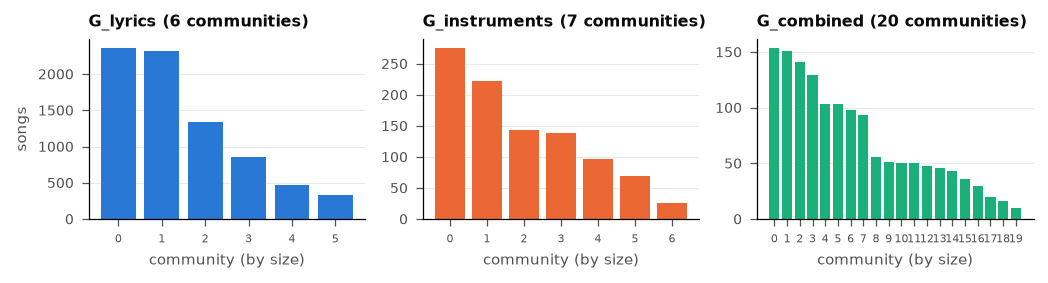

In [15]:
fig = plotting.size_panels({name: [len(c) for c in comms] for name, comms in partitions.items()},
                           name="community_sizes")

A first look at what the communities contain: the share of each evaluation genre per community (rows sum to 100%; songs without a genre left out). Step 5 measures the agreement properly (AMI, ARI, assortativity, heatmaps) for genre and country.

In [16]:
for name, g in lcc.items():
    print(name)
    display(cm.composition(g, "genre_eval").round(0).astype(int))

G_lyrics


label,country,electronic,folk,jazz,other,pop,rb,reggae,rock
community,,,,,,,,,
0,6,1,2,0,1,6,11,2,70
1,14,1,2,1,1,12,13,2,54
2,6,1,1,1,1,10,34,1,46
3,2,1,1,1,3,9,32,1,50
4,12,0,1,1,0,12,17,2,55
5,14,0,2,0,5,17,14,1,47


G_instruments


label,country,electronic,folk,jazz,other,pop,rb,reggae,rock
community,,,,,,,,,
0,0,1,1,2,2,12,8,1,74
1,2,0,0,9,0,15,17,1,56
2,36,0,4,0,2,8,2,0,48
3,0,0,1,1,0,3,8,1,87
4,15,0,3,0,1,3,1,2,74
5,6,5,0,2,0,17,8,3,61
6,0,0,4,0,4,4,4,8,77


G_combined


label,country,electronic,folk,jazz,other,pop,rb,reggae,rock
community,,,,,,,,,
0,1,1,2,0,1,2,3,1,89
1,1,1,2,1,0,8,7,0,80
2,16,0,1,0,0,9,3,1,70
3,1,1,0,0,0,13,4,1,81
4,6,1,2,0,0,6,13,0,73
5,2,0,0,0,1,13,4,0,80
6,1,0,0,0,2,12,2,0,82
7,1,0,0,0,0,7,4,1,87
8,4,0,0,0,0,9,7,2,79


## Step 5 — Communities vs genre and country

Each measure uses only the songs that have the label (`src/evaluation.py`).

- **AMI** (adjusted mutual information) and **ARI** (adjusted Rand index) between community and label. Both are 0 at chance level and 1 for identical partitions. AMI measures shared information; ARI measures how many pairs of songs are put together in both.
- **Heatmaps** of community × label, rows as percentages. Only communities with ≥ 10 songs are shown; country is cut to the 8 most common release countries plus "other".
- **Attribute assortativity** (`nx.attribute_assortativity_coefficient`): do links join songs with the same label more often than chance? It needs no communities, so it doesn't depend on Louvain. The networkx version ignores edge weights.
- **Modularity of the label partition** (`M_label`), next to Louvain's M, on the same songs. **Songs without the label are excluded**, i.e. both M values are computed on the subgraph of labelled songs. Putting them all in one "unknown" group would add an artificial genre. Giving each its own group would lower `M_label` for reasons that have nothing to do with genre.
- **Fair comparison.** The graphs contain different songs, so AMI is also computed on the songs that are in all three LCCs.

In [17]:
from src import evaluation as ev

GENRE_ORDER = list(lyr.genre_eval.value_counts().index)              # most common first
# the 8 most common release countries among the songs with lyrics; every song (also
# those without lyrics, in G_instruments) is mapped by its own country
TOP8 = list(songs.loc[songs.has_lyrics, "country"].value_counts().index[:8])
COUNTRY_ORDER = TOP8 + ["other"]
for g in lcc.values():
    nx.set_node_attributes(g, {n: c if c in TOP8 else "other"
                               for n, c in nx.get_node_attributes(g, "country").items()}, "country_top")

rows = {}
for name, g in lcc.items():
    r = {}
    for attr, key in [("genre_eval", "genre"), ("country", "country")]:
        a = ev.agreement(g, attr)
        m_label, m_louvain, n = ev.label_modularity(g, attr)
        r.update({f"n_{key}": a["n"], f"AMI_{key}": a["AMI"], f"ARI_{key}": a["ARI"],
                  f"assort_{key}": ev.assortativity(g, attr),
                  f"M_{key}_partition": m_label, f"M_louvain_on_{key}_songs": m_louvain})
    r["AMI_primary_genre"] = ev.agreement(g, "genre")["AMI"]   # finer check: 43 core genres
    rows[name] = r
step5 = pd.DataFrame(rows)
step5.T.to_csv(RESULTS_DIR / "step5_metadata.csv")
step5.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

,G_lyrics,G_instruments,G_combined
n_genre,"7,182",930,"1,417"
AMI_genre,0.03331,0.09625,0.01441
ARI_genre,0.04111,0.02447,0.004495
assort_genre,0.04349,0.07611,0.03525
M_genre_partition,0.03283,0.04666,0.02012
M_louvain_on_genre_songs,0.2073,0.4851,0.3706
n_country,"7,681",971,"1,428"
AMI_country,0.006766,0.01833,0.4032
ARI_country,0.008123,0.01507,0.1114
assort_country,0.0104,0.008129,0.3747


### Heatmaps

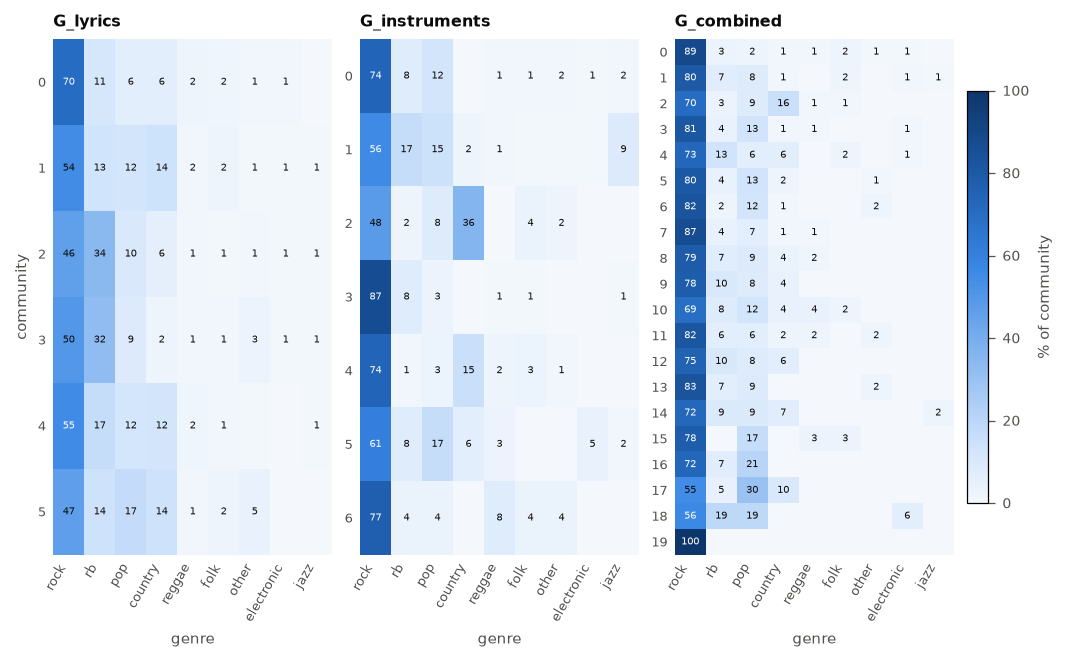

In [18]:
genre_tables = {name: cm.composition(g, "genre_eval").reindex(columns=GENRE_ORDER, fill_value=0)
                for name, g in lcc.items()}
fig = plotting.heatmap_panels(genre_tables, name="heatmap_genre", xlabel="genre")

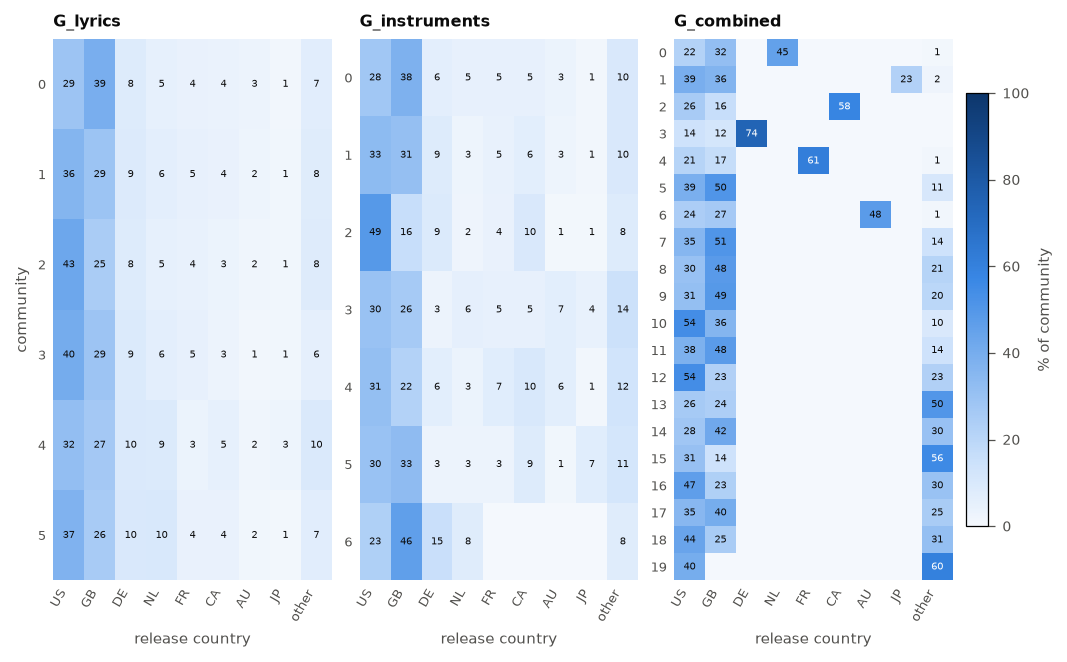

In [19]:
country_tables = {name: cm.composition(g, "country_top").reindex(columns=COUNTRY_ORDER, fill_value=0)
                  for name, g in lcc.items()}
fig = plotting.heatmap_panels(country_tables, name="heatmap_country", xlabel="release country")

For reference, the label mix of all songs in each LCC. A community stands out where its row differs from this baseline.

In [20]:
display(pd.DataFrame({name: ev.labelled(g, "genre_eval").label.value_counts(normalize=True).mul(100)
                      for name, g in lcc.items()}).reindex(GENRE_ORDER).round(0))
display(pd.DataFrame({name: ev.labelled(g, "country_top").label.value_counts(normalize=True).mul(100)
                      for name, g in lcc.items()}).reindex(COUNTRY_ORDER).round(0))

,G_lyrics,G_instruments,G_combined
label,,,
rock,57.0,67.0,79.0
rb,18.0,8.0,6.0
pop,10.0,10.0,9.0
country,9.0,8.0,4.0
reggae,2.0,1.0,1.0
folk,2.0,2.0,1.0
other,1.0,1.0,0.0
electronic,1.0,1.0,0.0
jazz,1.0,3.0,0.0


,G_lyrics,G_instruments,G_combined
label,,,
US,35.0,33.0,31.0
GB,31.0,30.0,31.0
DE,9.0,7.0,7.0
NL,6.0,4.0,5.0
FR,4.0,5.0,4.0
CA,4.0,7.0,6.0
AU,2.0,3.0,3.0
JP,1.0,2.0,2.0
other,7.0,11.0,11.0


### Fair comparison: the songs common to all three graphs

`G_lyrics`, `G_instruments` and `G_combined` contain different songs, and AMI depends on which songs are compared. The table below recomputes AMI and ARI on the songs that are in all three LCCs, each graph still using its own partition.

In [21]:
common = set.intersection(*(set(g.nodes) for g in lcc.values()))
print(f"{len(common)} songs are in all three LCCs")
step5_common = pd.DataFrame({name: {f"{m}_{key}": ev.agreement(g, attr, common)[m]
                                     for attr, key in [("genre_eval", "genre"), ("country", "country")]
                                     for m in ("AMI", "ARI")}
                             for name, g in lcc.items()})
step5_common.T.to_csv(RESULTS_DIR / "step5_common_songs.csv")
step5_common.round(4)

673 songs are in all three LCCs


,G_lyrics,G_instruments,G_combined
AMI_genre,0.0301,0.0871,0.0262
ARI_genre,0.0372,0.0144,0.0105
AMI_country,0.0006,0.0096,0.4081
ARI_country,0.0012,-0.0001,0.1310


## Step 6 — Genuine or random?

### 6A. Configuration-model null for modularity

Even a random graph has partitions with M > 0, and Louvain will find them. So Louvain's M on a real graph only means something when compared with M on random graphs that keep what is *not* community structure: every song's degree.

- **The null graphs.** Each null graph is the backbone LCC rewired with double edge swaps (`nx.double_edge_swap`, nswap = 10·|E|): two edges a–b and c–d become a–d and c–b, which keeps every degree. The real weights are then shuffled randomly over the new edges. Strengths are therefore only kept on average, a simplification for weighted graphs.
- **What we compute.** We run Louvain on 100 such graphs per graph, and report the mean and sd of the null M, the z-score z = (M_real − mean)/sd, and the empirical p-value (1 + #{M_null ≥ M_real}) / (1 + 100). The smallest possible p-value is 1/101 ≈ 0.0099.
- **Runtime and caching.** One `G_lyrics` null takes ≈ 17 s (162k edges, 1.6M swaps), so all 300 null models take about half an hour. The results are saved to `results/step6a_null_modularity.csv` and only recomputed if the file is missing or the environment variable `RERUN_NULLS=1` is set.

In [22]:
from src import nulls

N_NULL = 100
null_file = RESULTS_DIR / "step6a_null_modularity.csv"
if null_file.exists() and os.environ.get("RERUN_NULLS") != "1":
    null_M = pd.read_csv(null_file)
    print(f"Loaded {len(null_M)} null-model values from {null_file.name}")
else:
    null_M = pd.concat([pd.DataFrame({"graph": name, "null": range(N_NULL),
                                      "M": nulls.modularity_null(g, N_NULL, seed=SEED)})
                        for name, g in lcc.items()])
    null_M.to_csv(null_file, index=False)

M_real = {name: nx.community.modularity(g, partitions[name], weight="weight") for name, g in lcc.items()}
step6a = pd.DataFrame({name: nulls.null_summary(M_real[name], null_M.loc[null_M.graph == name, "M"].to_numpy())
                       for name in lcc})
step6a.T.to_csv(RESULTS_DIR / "step6a_modularity_null.csv")
step6a.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

Loaded 300 null-model values from step6a_null_modularity.csv


,G_lyrics,G_instruments,G_combined
M_real,0.2118,0.482,0.3706
M_null_mean,0.05546,0.06745,0.1795
M_null_sd,0.000848,0.001229,0.0009826
z,184.4,337.2,194.5
p,0.009901,0.009901,0.009901
n_null,100,100,100


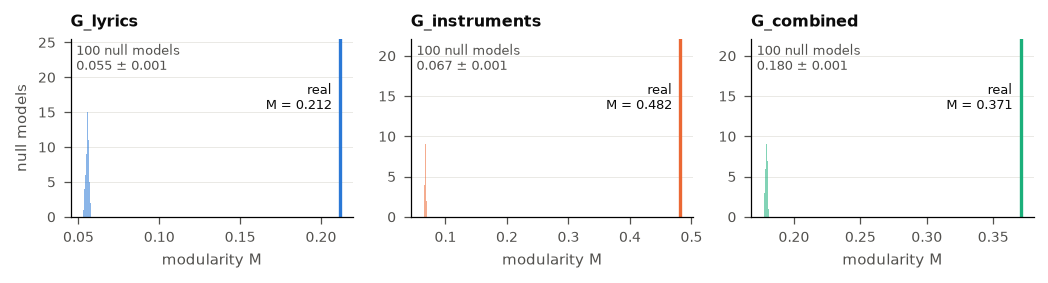

In [23]:
fig = plotting.null_panels({name: null_M.loc[null_M.graph == name, "M"].to_numpy() for name in lcc},
                           M_real, name="modularity_null")

### 6B. Permutation test for genre and country

Is the (small) agreement between communities and labels from Step 5 more than chance? The communities are kept fixed and the labels are shuffled over the songs 1,000 times. Each shuffle keeps how many songs each genre (or country) has. The AMI is recomputed after every shuffle, and the p-value is (1 + #{AMI_null ≥ AMI_real}) / (1 + 1000), so the smallest possible value is 1/1001 ≈ 0.001.

AMI is already corrected for chance, so the shuffled AMIs sit around 0. Their spread tells us how large an AMI chance alone can produce for this number of songs and communities. The test is run on each graph's own LCC (as in Step 5) and on the songs common to all three LCCs.

The whole test takes under a minute, so it is not cached.

In [24]:
N_PERM = 1000
perm_rows, perm_null = [], {"genre": {}, "country": {}}
for scope, nodes in [("LCC", None), ("common", common)]:
    for name, g in lcc.items():
        for attr, key in [("genre_eval", "genre"), ("country", "country")]:
            df = ev.labelled(g, attr, nodes)
            real, null, p = nulls.permutation_ami(df.label, df.community, N_PERM, seed=SEED)
            perm_rows.append({"scope": scope, "graph": name, "label": key, "n": len(df),
                              "AMI_real": real, "AMI_null_mean": null.mean(),
                              "AMI_null_sd": null.std(ddof=1), "AMI_null_max": null.max(),
                              "z": (real - null.mean()) / null.std(ddof=1), "p": p})
            if scope == "LCC":
                perm_null[key][name] = null
step6b = pd.DataFrame(perm_rows)
step6b.to_csv(RESULTS_DIR / "step6b_permutation_ami.csv", index=False)
step6b.set_index(["scope", "label", "graph"]).apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

n   AMI_real AMI_null_mean AMI_null_sd AMI_null_max       z         p
scope  label   graph                                                                                   
LCC    genre   G_lyrics       7,182    0.03331    -3.541e-06   0.0004379      0.00165    76.1  0.000999
       country G_lyrics       7,681   0.006766    -4.878e-05   0.0006501     0.001817   10.48  0.000999
       genre   G_instruments    930    0.09625    -8.405e-05    0.003391      0.01303   28.41  0.000999
       country G_instruments    971    0.01833    -3.408e-05     0.00389      0.01629   4.721  0.000999
       genre   G_combined     1,417    0.01441    -8.338e-05    0.002555     0.009781    5.67  0.000999
       country G_combined     1,428     0.4032     0.0001035    0.003415      0.01246     118  0.000999
common genre   G_lyrics         667    0.03005     0.0003214    0.004758      0.02131   6.248  0.000999
       country G_lyrics         673  0.0006024      -8.6e-05    0.005498      0.01757  0.1252    0.4296
       genre   G_instruments    667    0.08712    -6.027e-05    0.004418      0.01908   19.74  0.000999
       country G_instruments    673   0.009559     5.505e-06    0.005354      0.01464   1.784   0.04096
       genre   G_combined       667    0.02623     2.016e-05    0.005042       0.0179   5.199  0.000999
       country G_combined       673     0.4081      0.000197    0.006298      0.02154   64.77  0.000999

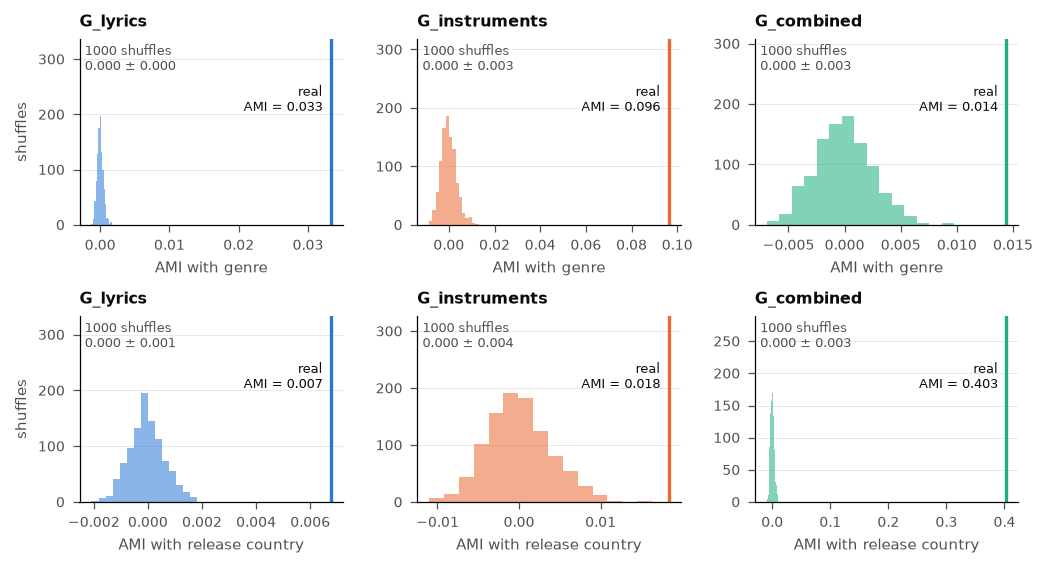

In [25]:
AMI_real = {key: {name: step6b.query("scope == 'LCC' and label == @key and graph == @name").AMI_real.item()
                  for name in lcc} for key in perm_null}
fig = plotting.null_grid(perm_null, AMI_real, name="ami_permutation", symbol="AMI",
                         what="shuffles", xlabels={"genre": "AMI with genre",
                                                   "country": "AMI with release country"})

### 6C. Stability

Are the communities a property of the data, or of one particular run? Three checks (`src/robustness.py`):

1. **Seeds.** Louvain is randomised, so we run it with 20 seeds (`SEED` … `SEED`+19) on each backbone LCC. We report the mean AMI over all 190 pairs of partitions (1 = always the same partition), and the mean ± sd of M, the number of communities and the AMI with genre and country.
2. **Disparity-filter level α.** Each backbone is rebuilt at α = 0.01, 0.05 and 0.1, and Louvain is run with `SEED` on its LCC. A smaller α keeps fewer edges, so the LCC loses songs. AMI is therefore computed on different song sets per α, and only the direction of change should be read from it.
3. **Country weight in `G_combined`.** Country dominates `G_combined`'s communities (Step 5). We rebuild `G_combined` with the country projection scaled by 1 (main result), 0.5, 0.25 and 0 (country left out; only words and instruments). The rest of the pipeline is unchanged (backbone at α = 0.05, LCC, Louvain with `SEED`). This shows how much genre signal is hidden behind country.

In [26]:
from src import robustness as rb

SEEDS = range(SEED, SEED + 20)
seed_rows, stability = [], {}
for name, g in lcc.items():
    df, members = rb.seed_runs(g, SEEDS)
    seed_rows.append(df.assign(graph=name))
    pair = rb.pairwise_ami(members)
    stability[name] = {"stability_AMI": pair.mean(), "stability_AMI_min": pair.min(),
                       **{f"{c}_mean": df[c].mean() for c in ["M", "n_communities", "AMI_genre", "AMI_country"]},
                       **{f"{c}_sd": df[c].std(ddof=1) for c in ["M", "n_communities", "AMI_genre", "AMI_country"]}}
pd.concat(seed_rows).to_csv(RESULTS_DIR / "step6c_seeds.csv", index=False)
step6c_seeds = pd.DataFrame(stability)
step6c_seeds.T.to_csv(RESULTS_DIR / "step6c_stability.csv")
step6c_seeds.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

,G_lyrics,G_instruments,G_combined
stability_AMI,0.6206,0.904,0.5789
stability_AMI_min,0.4578,0.7527,0.4717
M_mean,0.2109,0.4805,0.3664
n_communities_mean,7.25,7.8,18.7
AMI_genre_mean,0.02854,0.09273,0.01631
AMI_country_mean,0.005526,0.01666,0.4002
M_sd,0.002178,0.003984,0.005704
n_communities_sd,0.6387,0.4104,1.174
AMI_genre_sd,0.002479,0.006374,0.002969
AMI_country_sd,0.000868,0.001499,0.008668


In [27]:
ALPHAS = [0.01, 0.05, 0.1]
step6c_alpha = pd.DataFrame([{"graph": name, "alpha": a, **rb.alpha_run(P[name], a, SEED)}
                             for name in lcc for a in ALPHAS])
step6c_alpha.to_csv(RESULTS_DIR / "step6c_alpha.csv", index=False)
step6c_alpha.set_index(["graph", "alpha"]).apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

n_nodes    n_edges       M n_communities n_communities_ge10 AMI_genre AMI_country
graph         alpha                                                                                  
G_lyrics      0.01    7,680  1.601e+05  0.3372            20                 20   0.01597    0.002792
              0.05    7,681  9.926e+05  0.2118             6                  6   0.03331    0.006766
              0.10    7,681  2.438e+06  0.1633             6                  6   0.02613    0.005115
G_instruments 0.01      554  1.192e+04  0.6271             6                  6    0.1024     0.02246
              0.05      971  5.425e+04   0.482             7                  7   0.09625     0.01833
              0.10      995  9.651e+04  0.4138             7                  7    0.1026     0.01863
G_combined    0.01    1,428  3.691e+04  0.3975            19                 19    0.0179      0.4012
              0.05    1,428   4.64e+04  0.3706            20                 20   0.01441      0.4032
              0.10    1,428  5.266e+04  0.3573            17                 17   0.01719      0.4031

In [28]:
COUNTRY_WEIGHTS = [1, 0.5, 0.25, 0]
rows = []
for w in COUNTRY_WEIGHTS:
    g = graphs.add_metadata(graphs.balanced_projection(combined_feats, type_weights={"country": w}), songs)
    g = bb.largest_component(bb.backbone(bb.disparity_pvalues(g), ALPHA))
    shares = graphs.type_shares(g)
    rows.append({"country_weight": w, **rb.partition_row(g, cm.louvain(g, SEED)),
                 **{f"share_{t}": s for t, s in shares.items()}})
step6c_country = pd.DataFrame(rows)
step6c_country.to_csv(RESULTS_DIR / "step6c_country_weight.csv", index=False)
step6c_country.set_index("country_weight").apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

,n_nodes,n_edges,M,n_communities,n_communities_ge10,AMI_genre,AMI_country,share_inst,share_country,share_word
country_weight,,,,,,,,,,
1.00,"1,428",4.64e+04,0.3706,20,20,0.01441,0.4032,0.03719,0.2823,0.6805
0.50,"1,428",4.796e+04,0.2305,20,20,0.007332,0.1354,0.04527,0.1594,0.7954
0.25,"1,428",4.071e+04,0.2319,20,20,0.002509,0.02557,0.04627,0.0559,0.8978
0.00,"1,428",3.699e+04,0.2416,22,22,0.008271,0.001949,0.04842,0,0.9516


### 6D. Content check: what do the communities contain?

Each community with at least 10 songs is described by its lyrics (words and sentiment) and, for the graphs that use instruments, by its instrument families (`src/content.py`).

- **Distinctive words.** The communities of one graph are compared with TF-IDF, with each community as one document. TF counts *how many of the community's songs* use a word (once per song), and IDF = log(number of communities / communities using the word). Plain TF-IDF on the merged lyrics was tried first and gave names and words from single songs ("chh", "suzanne", "ding dong"): one song repeating a word 40 times outweighed a word used by 30 songs. A word used in every community gets IDF 0. Only words used by at least 5 songs of the graph are considered. Word clouds show the 40 top words, sized by score.
- **Sentiment.** VADER is built for short texts: on a whole song its compound score saturates at −1 or +1. Each lyric line is therefore scored on its own, and a song's sentiment is the mean compound score of its lines. VADER is run on the raw lyrics, because capitals, punctuation and negations ("not") change the score.
- **Do communities differ in sentiment?** Song scores are shuffled over the songs 1,000 times, keeping the group sizes, and the spread of the group means (between-group sum of squares) is compared with the real one. We report the p-value and the share of the sentiment variance that lies between the groups (η²). The same is done for genre.

In [29]:
from src import content

members = {name: cm.membership(partitions[name]) for name in lcc}
tfidf_scores, word_rows = {}, []
for name in lcc:
    groups = content.community_tokens(members[name], lyr.tokens)
    tfidf_scores[name] = content.community_tfidf(groups)
    sizes = pd.Series(members[name]).value_counts()
    for c, words in content.top_words(tfidf_scores[name], 10).items():
        word_rows.append({"graph": name, "community": c, "songs": sizes[c],
                          "songs_with_lyrics": len(groups[c]), "top_words": words})
step6d_words = pd.DataFrame(word_rows)
step6d_words.to_csv(RESULTS_DIR / "step6d_top_words.csv", index=False)
with pd.option_context("display.max_colwidth", None):
    display(step6d_words.set_index(["graph", "community"]))

songs  songs_with_lyrics                                                                       top_words
graph         community                                                                                                          
G_lyrics      0           2366               2366         orders police bullets sheriff deal traffic war culture revenge suburban
              1           2323               2323                   autumn sigh lands sorrows om tho shared scattered loser naked
              2           1345               1345                ichi exist darlin squeeze lovin lightnin ooooooh shi beggin fake
              3            856                856                mic mc disco mcs def females microphone socialize funk viciously
              4            463                463     barroom husband naked shreds government tonk grave braggin cases hypocrites
              5            328                328               ding dong sleigh sings dis dishes advertising airwaves dat firmly
G_instruments 0            276                184                    tender hell drift heavy kisses suit talked said need fooling
              1            222                145                  suddenly fair promise walked fever paint wise need carly simon
              2            143                103                    drown scars smiled candle sang stole walls roll started past
              3            138                 99                   risk need said lake shoot threw went dreaming moving creeping
              4             96                 78                 fields middle smiles clothes little said eating rising san shed
              5             70                 48                fantasy locked rough sail suddenly air water climb sailing thing
              6             26                 16            beer creeping spare gun tricks women agree christmas crossed million
G_combined    0            154                154              loneliness zoo disease torn beating picked thrown wife breaks ahhh
              1            151                151                 solo letter anger signed rises sees ought sittin thrill address
              2            141                141              buddy growin melt moves barely finds somebody eyed flashing headin
              3            129                129           anger washed shoot lend reputation turnin following harm beauty grace
              4            103                103                     cracks funk killer lean nasty drugs teeth shine candy facts
              5            103                103         delight flames field eternal instant seas waving feelings bible journey
              6             98                 98                      wrote food daytime east bore building farm freak gods quit
              7             93                 93  johnny melting ended abuse gambling perfection conversation familiar de glance
              8             56                 56           revolution brothers drug cling tower barrel quickly works special box
              9             51                 51     forest video hurry america stumble tune restless spark understanding rhythm
              10            50                 50                  kite manhattan stuck ashamed bow tonk razor tread dollar glory
              11            50                 50         horizon teacher signed lee weird grows aside concrete confidence freeze
              12            48                 48                aim sung trap husband mountain quiet followed tumble wisdom cake
              13            46                 46            certain emotions survive bites float private roads routine shape sly
              14            43                 43             action feelin daytime buried couple fault notes stone holy received
              15            36                 36         president biggest eyed police dirt risin dollars sidewalk clown hel

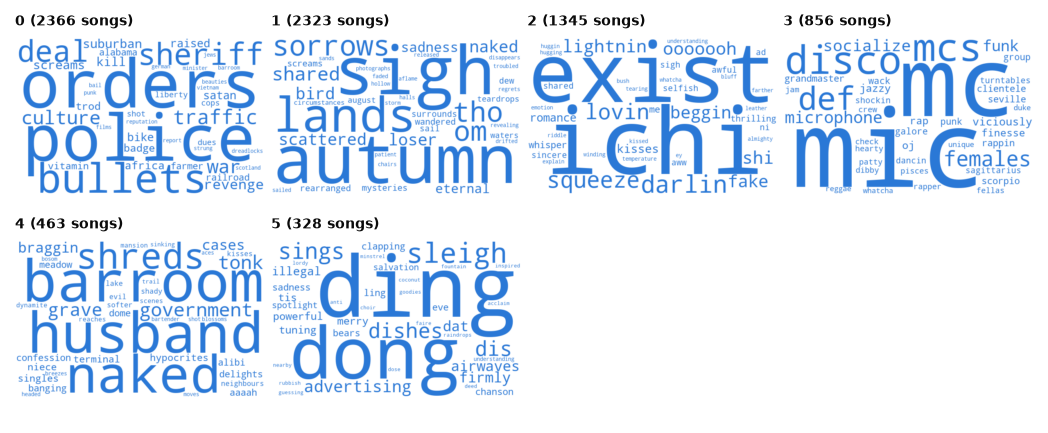

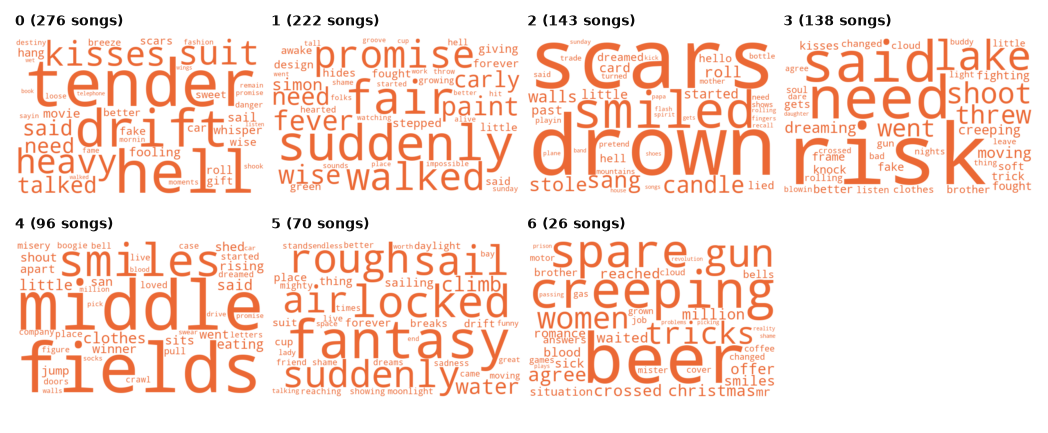

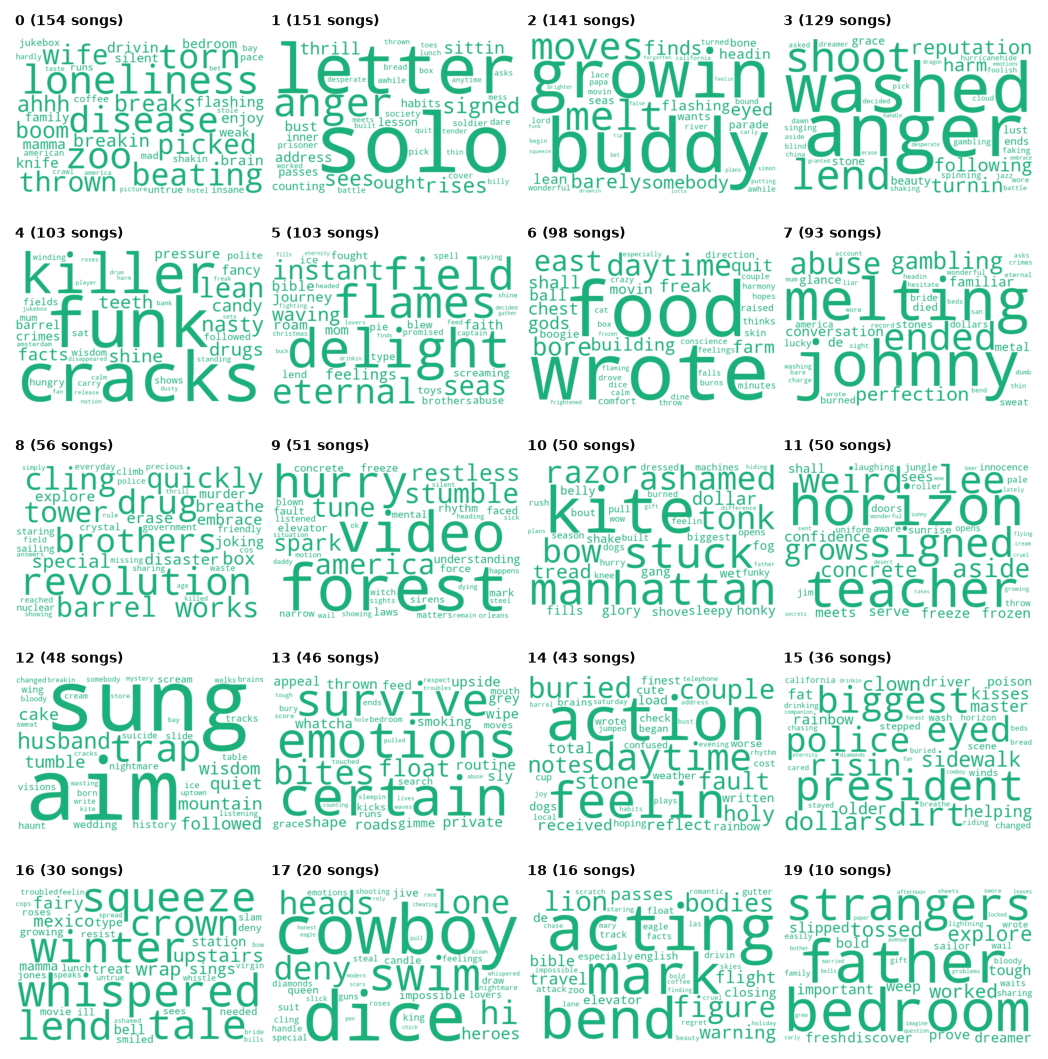

In [30]:
import matplotlib.pyplot as plt

for name in lcc:
    sizes = pd.Series(members[name]).value_counts()
    titles = {c: f"{c} ({sizes[c]} songs)" for c in tfidf_scores[name].index}
    plotting.wordcloud_grid({c: row for c, row in tfidf_scores[name].iterrows()},
                            name=f"wordclouds_{name}", color=plotting.GRAPH_COLORS[name],
                            titles=titles, seed=SEED)
    plt.show()

In [31]:
sentiment = lyr.lyrics.map(content.song_sentiment).rename("sentiment")
sentiment.to_csv(RESULTS_DIR / "step6d_sentiment_songs.csv")
print(sentiment.describe().round(3).to_string())

N_PERM = 1000
box, sent_rows = {}, []
for name in lcc:
    big = set(tfidf_scores[name].index)                       # communities with >= 10 songs
    m = pd.Series(members[name]).reindex(sentiment.index).dropna()
    m = m[m.isin(big)].astype(int)
    v = sentiment.reindex(m.index).dropna(); m = m[v.index]
    box[name] = {str(c): v[m == c].to_numpy() for c in sorted(big)}
    ss, eta2, p = content.permutation_groups(v, m, N_PERM, SEED)
    sent_rows.append({"grouping": name, "n_songs": len(v), "groups": len(big), "eta2": eta2, "p": p})
g = lyr.genre_eval.reindex(sentiment.index).dropna()
box["genre"] = {k: sentiment[g[g == k].index].to_numpy() for k in GENRE_ORDER}
ss, eta2, p = content.permutation_groups(sentiment[g.index], g, N_PERM, SEED)
sent_rows.append({"grouping": "genre", "n_songs": len(g), "groups": g.nunique(), "eta2": eta2, "p": p})
step6d_sentiment = pd.DataFrame(sent_rows)
step6d_sentiment.to_csv(RESULTS_DIR / "step6d_sentiment_test.csv", index=False)
display(step6d_sentiment.round(4))
display(pd.DataFrame({k: {grp: np.median(vals) for grp, vals in d.items()} for k, d in box.items()}).round(3))

count    7682.000
mean        0.087
std         0.142
min        -0.746
25%         0.004
50%         0.073
75%         0.162
max         0.998


,grouping,n_songs,groups,eta2,p
0,G_lyrics,7681,6,0.0828,0.0010
1,G_instruments,673,7,0.0148,0.1129
2,G_combined,1428,20,0.0196,0.0759
3,genre,7183,9,0.0411,0.0010


,G_lyrics,G_instruments,G_combined,genre
0,0.035,0.078,0.062,NaN
1,0.077,0.076,0.047,NaN
2,0.139,0.082,0.072,NaN
3,0.074,0.046,0.071,NaN
4,0.096,0.048,0.055,NaN
5,0.104,0.066,0.038,NaN
6,NaN,0.010,0.076,NaN
7,NaN,NaN,0.046,NaN
8,NaN,NaN,0.075,NaN
9,NaN,NaN,0.071,NaN


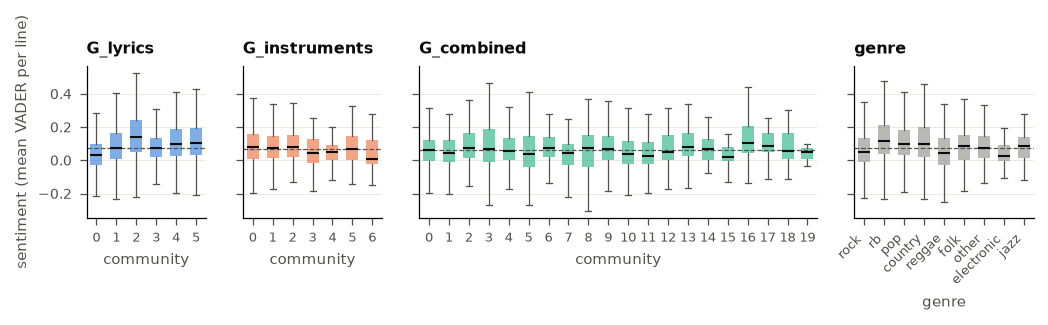

In [32]:
fig = plotting.box_panels(box, name="sentiment_boxplots", ylabel="sentiment (mean VADER per line)",
                          colors={"genre": "#8a8985"},
                          xlabels={name: "community" for name in lcc} | {"genre": "genre"})

**Instrument profile.** For the two graphs built (partly) from instruments: the share of each community's songs that has each instrument family. Unlike the heatmaps in Step 5, rows do not sum to 100 %, because a song has several families.

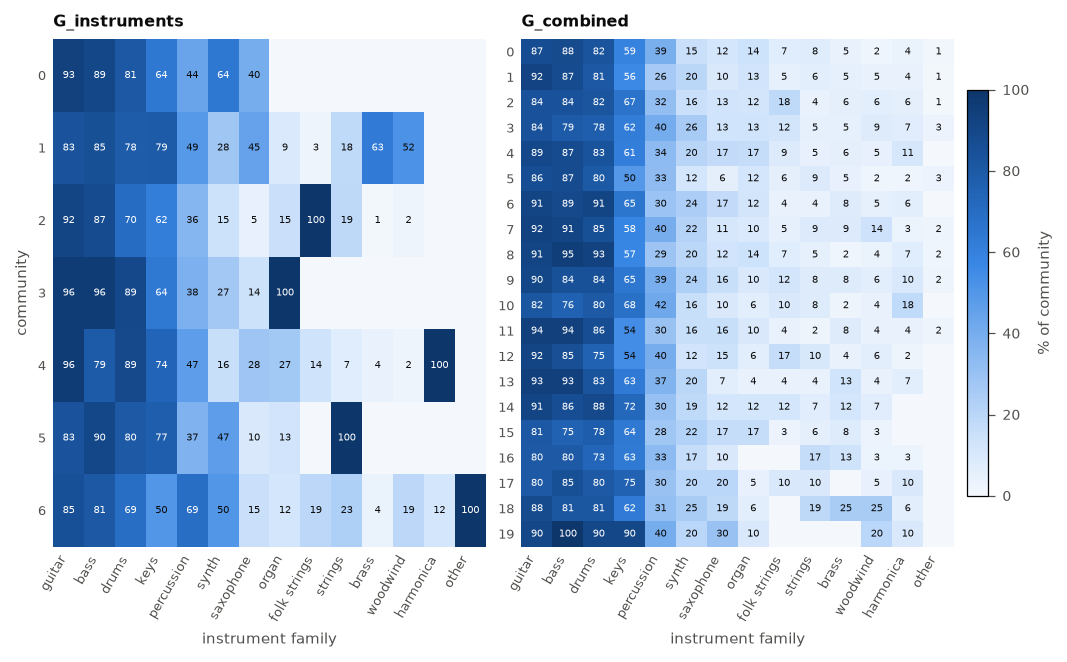

In [33]:
FAMILY_ORDER = list(songs.instrument_families.dropna().str.get_dummies(sep=";").mean()
                    .sort_values(ascending=False).index)
profiles = {name: content.family_profile(members[name], songs.instrument_families)
                  .reindex(columns=FAMILY_ORDER, fill_value=0)
            for name in ["G_instruments", "G_combined"]}
pd.concat(profiles, names=["graph", "community"]).round(1).to_csv(RESULTS_DIR / "step6d_instrument_profile.csv")
fig = plotting.heatmap_panels(profiles, name="instrument_profile", xlabel="instrument family")

## Step 7 — Associations between instrument, country and theme

Which instrument families go together with which release countries and which lyrical themes? The themes are the `G_lyrics` communities from Step 4, each labelled by its two top words from 6D (see the word clouds). Genre is not used. All counts are songs (`src/associations.py`).

- **Song sets.** Instrument × country uses the 2,171 songs with instrument data (all have a country). Instrument × theme uses the 1,428 of them that also have lyrics. Countries with fewer than 15 of these songs are grouped as "other", so that no column rests on a handful of songs.
- **Lift** = P(A and B) / (P(A) P(B)) = n(A, B)·N / (n(A)·n(B)). Lift 1 means family A is exactly as common in country (or theme) B as overall, and lift 2 means twice as common. The heatmap uses a log scale, so 2 and ½ are equally far from 1. Cells with fewer than 5 songs are left blank.
- **Chi-square per family.** A song usually has several families, so one families × labels table would count songs several times. Each family is therefore tested separately in a 2 × K table (family present / absent × country or theme), where every song is counted once. Many cells have expected counts below 5, so the chi-square p-value is checked with a permutation p-value (1,000 label shuffles). Both are also Bonferroni-corrected for the number of families tested. Cramér's V gives the strength (0 = none, 1 = perfect).

In [34]:
from src import associations as asc

F = asc.family_matrix(songs.instrument_families)
cc = songs.country.reindex(F.index)
big_countries = cc.value_counts()[lambda s: s >= 15].index
country7 = cc.where(cc.isin(big_countries), "other")
C_ORDER = list(big_countries) + ["other"]

theme_words = step6d_words[step6d_words.graph == "G_lyrics"].set_index("community").top_words
THEME = {c: f"{c} {' '.join(w.split()[:2])}" for c, w in theme_words.items()}
theme = pd.Series(members["G_lyrics"]).map(THEME).reindex(F.index).dropna()
T_ORDER = [THEME[c] for c in sorted(THEME)]
print(f"instrument x country: {len(country7)} songs, {len(C_ORDER)} countries; "
      f"instrument x theme: {len(theme)} songs, {theme.nunique()} themes")

assoc = {"country": (F, country7, C_ORDER), "theme": (F.loc[theme.index], theme, T_ORDER)}
lifts, ns, tests = {}, {}, []
for key, (Fk, lab, order) in assoc.items():
    lifts[key] = asc.lift(Fk, lab).reindex(columns=order)
    ns[key] = asc.counts(Fk, lab).reindex(columns=order)
    tests.append(asc.family_tests(Fk, lab, N_PERM, SEED).assign(label=key))
    pd.concat({"n": ns[key], "lift": lifts[key]}, axis=1).round(3).to_csv(RESULTS_DIR / f"step7_lift_instrument_{key}.csv")
step7_tests = pd.concat(tests)[["label", "family", "songs", "chi2", "dof", "p_chi2", "p_chi2_bonf",
                                "p_perm", "p_perm_bonf", "cramers_v", "share_expected_lt5"]]
step7_tests.to_csv(RESULTS_DIR / "step7_chi2.csv", index=False)
step7_tests.set_index(["label", "family"]).apply(lambda col: col.map(lambda x: f"{x:,.3g}"))

instrument x country: 2171 songs, 12 countries; instrument x theme: 1428 songs, 6 themes


songs  chi2 dof    p_chi2 p_chi2_bonf    p_perm p_perm_bonf cramers_v share_expected_lt5
label   family                                                                                                   
country folk strings       167  69.8  11  1.35e-10    1.89e-09  0.000999       0.014     0.179              0.167
        keys          1.19e+03  66.2  11  6.46e-10    9.04e-09  0.000999       0.014     0.175                  0
        bass          1.86e+03  58.9  11   1.5e-08     2.1e-07  0.000999       0.014     0.165              0.125
        organ              219  33.5  11   0.00044     0.00617     0.004      0.0559     0.124              0.167
        guitar        1.91e+03  31.6  11  0.000877      0.0123  0.000999       0.014     0.121              0.125
        strings            151  30.5  11   0.00131      0.0184     0.003       0.042     0.119              0.208
        harmonica           99  24.8  11   0.00977       0.137     0.018       0.252     0.107              0.292
        synth              382  23.9  11    0.0132       0.185   0.00599      0.0839     0.105              0.125
        drums         1.67e+03  23.8  11    0.0137       0.192     0.014       0.196     0.105             0.0417
        woodwind           125  18.9  11     0.063       0.882    0.0679       0.951    0.0933              0.208
        brass              145  17.6  11    0.0921           1    0.0839           1      0.09              0.208
        saxophone          274  17.2  11     0.103           1    0.0989           1    0.0889              0.125
        percussion         751    16  11      0.14           1     0.152           1    0.0859                  0
        other               26  9.52  11     0.574           1     0.497           1    0.0662              0.417
theme   percussion         487  19.7   5   0.00143      0.0201     0.003       0.042     0.117                  0
        bass          1.23e+03  17.7   5   0.00341      0.0477     0.005      0.0699     0.111                  0
        keys               870  17.5   5   0.00361      0.0505     0.005      0.0699     0.111                  0
        strings             94  16.8   5   0.00493       0.069     0.004      0.0559     0.108             0.0833
        drums         1.18e+03  15.7   5   0.00764       0.107   0.00999        0.14     0.105                  0
        guitar        1.26e+03  12.2   5    0.0323       0.452      0.03        0.42    0.0924                  0
        folk strings       120  11.6   5    0.0411       0.576     0.046       0.643      0.09             0.0833
        saxophone          181  11.1   5    0.0489       0.684     0.046       0.643    0.0883                  0
        organ              165  7.65   5     0.176           1     0.156           1    0.0732                  0
        synth              270  7.46   5     0.189           1     0.192           1    0.0723                  0
        brass               91  6.51   5      0.26           1      0.24           1    0.0675             0.0833
        harmonica           80  4.93   5     0.425           1      0.44           1    0.0587             0.0833
        woodwind            81   4.4   5     0.494           1     0.474           1    0.0555             0.0833
        other               16  4.31   5     0.505           1     0.491           1     0.055              0.417

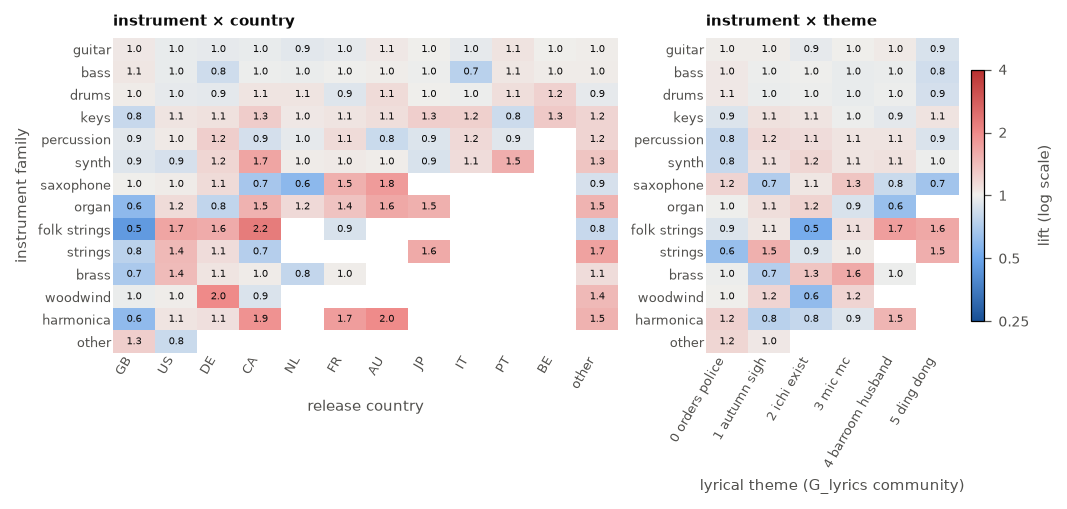

In [35]:
# the most frequent families: all with at least 20 songs, most common first
FAM_ORDER = [f for f in F.sum().sort_values(ascending=False).index if F[f].sum() >= 20]
fig = plotting.lift_heatmaps({"instrument × country": lifts["country"].reindex(FAM_ORDER),
                              "instrument × theme": lifts["theme"].reindex(FAM_ORDER)},
                             {"instrument × country": ns["country"], "instrument × theme": ns["theme"]},
                             name="lift_heatmap", xlabels={"instrument × country": "release country",
                                                           "instrument × theme": "lyrical theme (G_lyrics community)"})

## Step 8 — Summary

One row per graph, collected from Steps 4–6 (nothing is recomputed). All values are for the backbone LCC at α = 0.05 and the Louvain partition with `SEED`.

| column | meaning | step |
|---|---|---|
| `n_nodes`, `n_edges` | size of the backbone LCC | 2 |
| `M_real`, `M_null_mean`, `M_null_sd`, `z` | Louvain modularity vs 100 configuration-model nulls | 4, 6A |
| `n_communities` | Louvain communities (all sizes) | 4 |
| `AMI_genre`, `ARI_genre`, `AMI_country` | agreement of communities with labels | 5 |
| `p_genre`, `p_country` | permutation p-value of the AMI (1,000 shuffles; minimum ≈ 0.001) | 6B |
| `assort_genre`, `assort_country` | attribute assortativity of the links | 5 |
| `M_genre_partition` | modularity of genre used as the partition (labelled songs only) | 5 |
| `stability_AMI` | mean pairwise AMI of 20 Louvain seeds | 6C |

In [36]:
p6b = step6b[step6b.scope == "LCC"].set_index(["graph", "label"])
summary = pd.DataFrame({name: {
    "n_nodes": g.number_of_nodes(), "n_edges": g.number_of_edges(),
    "M_real": step6a.loc["M_real", name], "M_null_mean": step6a.loc["M_null_mean", name],
    "M_null_sd": step6a.loc["M_null_sd", name], "z": step6a.loc["z", name],
    "n_communities": len(partitions[name]),
    "AMI_genre": step5.loc["AMI_genre", name], "p_genre": p6b.loc[(name, "genre"), "p"],
    "ARI_genre": step5.loc["ARI_genre", name],
    "AMI_country": step5.loc["AMI_country", name], "p_country": p6b.loc[(name, "country"), "p"],
    "assort_genre": step5.loc["assort_genre", name], "assort_country": step5.loc["assort_country", name],
    "M_genre_partition": step5.loc["M_genre_partition", name],
    "stability_AMI": step6c_seeds.loc["stability_AMI", name]} for name, g in lcc.items()}).T
# the AMIs of Step 5 and of the permutation test must be the same numbers
for key in ["genre", "country"]:
    assert np.allclose(summary[f"AMI_{key}"].astype(float),
                       [p6b.loc[(n, key), "AMI_real"] for n in summary.index])
summary.index.name = "graph"
summary.to_csv(RESULTS_DIR / "summary.csv")
summary.T.apply(lambda col: col.map(lambda x: f"{x:,.4g}"))

graph,G_lyrics,G_instruments,G_combined
n_nodes,"7,681",971,"1,428"
n_edges,9.926e+05,5.425e+04,4.64e+04
M_real,0.2118,0.482,0.3706
M_null_mean,0.05546,0.06745,0.1795
M_null_sd,0.000848,0.001229,0.0009826
z,184.4,337.2,194.5
n_communities,6,7,20
AMI_genre,0.03331,0.09625,0.01441
p_genre,0.000999,0.000999,0.000999
ARI_genre,0.04111,0.02447,0.004495


## Report figures

The same results drawn for one PNAS column (8.7 cm), for the report. The figures above are two columns wide and would be shrunk to half size in one column. Saved as `figures/report_*.pdf`.

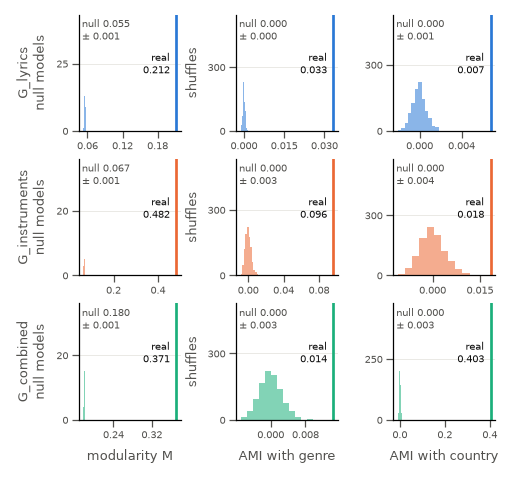

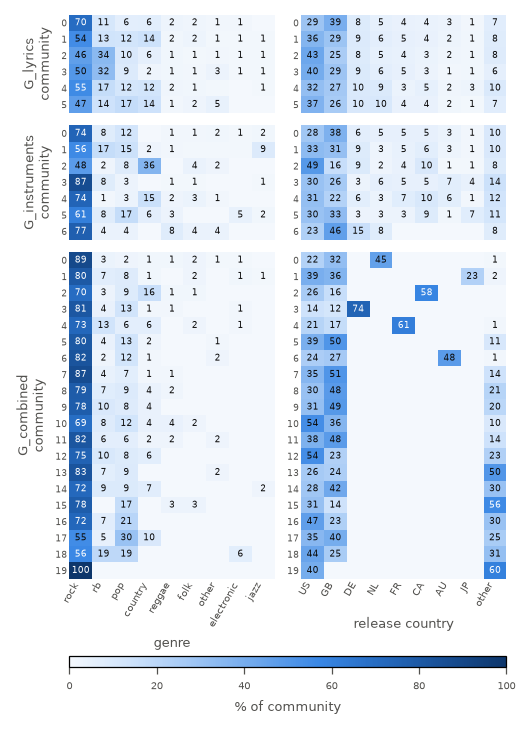

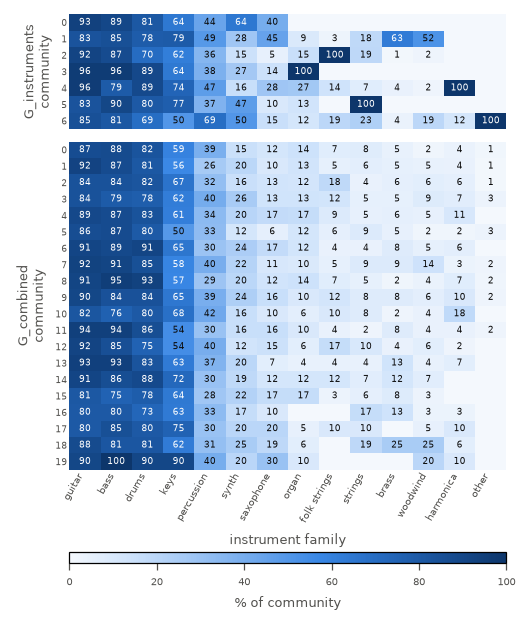

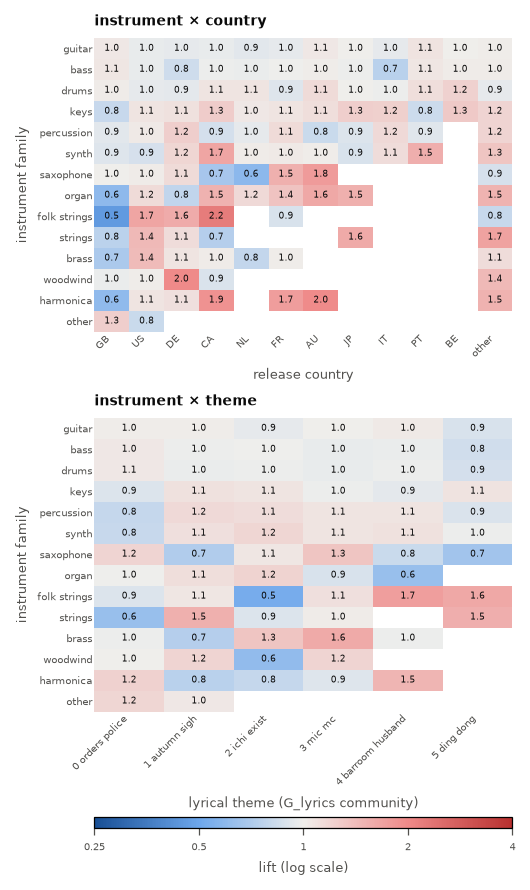

In [37]:
fig = plotting.null_matrix(
    {"M": {name: null_M.loc[null_M.graph == name, "M"].to_numpy() for name in lcc}} | perm_null,
    {"M": M_real} | AMI_real, name="report_null_checks",
    xlabels={"M": "modularity M", "genre": "AMI with genre", "country": "AMI with country"},
    whats={"M": "null models", "genre": "shuffles", "country": "shuffles"})
fig = plotting.heatmap_grid({"genre": genre_tables, "release country": country_tables},
                            name="report_heatmaps")
fig = plotting.heatmap_grid({"instrument family": profiles}, name="report_instrument_profile")
fig = plotting.lift_heatmaps({"instrument × country": lifts["country"].reindex(FAM_ORDER),
                              "instrument × theme": lifts["theme"].reindex(FAM_ORDER)},
                             {"instrument × country": ns["country"], "instrument × theme": ns["theme"]},
                             name="report_lift", column=True,
                             xlabels={"instrument × country": "release country",
                                      "instrument × theme": "lyrical theme (G_lyrics community)"})